In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

FOLDER = r"C:\Users\Lenovo\Downloads\PAn1\viz"   # đổi cho đúng
os.chdir(FOLDER)

print(os.getcwd())
for f in sorted(os.listdir(".")):
    print(f, "-", round(os.path.getsize(f) / 1024), "KB")

C:\Users\Lenovo\Downloads\PAn1\viz
feature_dictionary.csv - 9 KB
viz_films_long.csv - 5214 KB
viz_pairs.csv - 16999 KB
viz_schema.csv - 9 KB


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
FOLDER = r"C:\Users\Lenovo\Downloads\PAn1\viz"
os.chdir(FOLDER)
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
pd.set_option("display.max_colwidth", 120, "display.width", 200)

schema = pd.read_csv("viz_schema.csv")
fd = pd.read_csv("feature_dictionary.csv")
print(schema.shape, fd.shape)
print(schema.to_string())
print(fd.to_string())

(73, 8) (38, 15)
                               column    dtype                      role                                                                                                                                                           description           prediction_time                                         status  n_nonmissing  pct_missing
0                          Y_official  float64               viz_derived                                                                                           Y chinh thuc tu Task 4 (confirmed + comparable). Rong den khi team xac minh                       NaN                                       OFFICIAL             0       100.00
1            Y_exploratory_UNVERIFIED  float64               viz_derived                                  ln(open_curr)-ln(open_prev) khi ca hai opening duong; LAY NGUYEN tu Task 4 (khong ghi de); CHUA xac minh pair/market/currency/window                       NaN                                     UNVE

In [3]:
vp = pd.read_csv("viz_pairs.csv", low_memory=False)
print(vp.shape)
print(vp["viz_group"].value_counts())
print(vp["evidence_tier"].value_counts())
print(vp["y_exploratory_status"].value_counts())

pool = vp[(vp["viz_group"] == "pool_unblocked") & vp["Y_exploratory_UNVERIFIED"].notna()].copy()
print("Cặp pool có Y thăm dò:", len(pool), "| số collection:", pool["tmdb_collection_id"].nunique())
print(pool["Y_exploratory_UNVERIFIED"].describe().round(3))
print("Y_official có giá trị:", vp["Y_official"].notna().sum())

(30113, 67)
viz_group
other                    29081
pool_unblocked             918
both_open_but_blocked      114
Name: count, dtype: int64
evidence_tier
NO_Y                      29081
EXPLORATORY_UNVERIFIED     1032
Name: count, dtype: int64


KeyError: 'y_exploratory_status'

In [4]:
print(vp.shape)
print(list(vp.columns))
missing_cols = [c for c in schema["column"] if c not in vp.columns]
print("Cột có trong schema nhưng không có trong viz_pairs.csv:", missing_cols)
print(vp["viz_group"].value_counts())
print(vp["evidence_tier"].value_counts())

(30113, 67)
['tmdb_collection_id', 'pair_index_in_collection', 'film_key_prev', 'film_key_curr', 'title_prev', 'title_curr', 'release_date_prev', 'release_date_curr', 'candidate_class', 'block_reason', 'candidate_status', 'open_status_prev', 'open_status_curr', 'both_openings_positive_valid', 'y_reason', 'Y', 'Y_status', 'Y_reason', 'pool_unblocked_both_open_positive', 'installment_index_candidate', 'collection_n_films', 'collection_tier', 'gap_years', 'long_gap_flag', 'release_month_curr', 'release_month_prev', 'same_release_month', 'director_change', 'director_jaccard', 'cast_retention_top5', 'cast_overlap_n', 'company_jaccard', 'genre_jaccard', 'budget_prev', 'budget_curr', 'log_budget_ratio', 'log_open_prev', 'log_global_gross_prev', 'rt_critic_prev', 'rt_audience_prev', 'rt_critic_curr', 'rt_audience_curr', 'rt_critic_delta', 'rt_audience_delta', 'rt_status_prev', 'rt_status_curr', 'log1p_votes_prev', 'log1p_votes_curr', 'n_pairs_in_collection', 'n_pool_pairs_in_collection', 'prev

In [5]:
print(vp["Y_status"].value_counts(dropna=False))
print(vp["Y_reason"].value_counts(dropna=False).head(10))
print("Số cặp có Y:", vp["Y"].notna().sum())
print(pd.crosstab(vp["viz_group"], vp["Y"].notna()))

pool = vp[(vp["viz_group"] == "pool_unblocked") & vp["Y"].notna()].copy()
print("Cặp pool có Y:", len(pool), "| số collection:", pool["tmdb_collection_id"].nunique())
print(pool["Y"].describe().round(3))
print(pool[["title_prev", "title_curr", "open_prev", "open_curr", "Y"]].head(8).to_string())

Y_status
MISSING                                29081
EXPLORATORY_UNVERIFIED                   918
EXPLORATORY_UNVERIFIED_BLOCKED_PAIR      114
Name: count, dtype: int64
Y_reason
OPEN_PREV_MISSING|OPEN_CURR_MISSING                                                                                                                             18283
OPEN_PREV_NO_ROW_IN_DETAILED|OPEN_CURR_NO_ROW_IN_DETAILED                                                                                                        7034
OPEN_PREV_MISSING|OPEN_CURR_NO_ROW_IN_DETAILED                                                                                                                   1714
OPEN_PREV_NO_ROW_IN_DETAILED|OPEN_CURR_MISSING                                                                                                                   1001
computed from positive openings; NOT official because: PAIR_NOT_VERIFIED(not_reviewed)|OPENING_COMPARABILITY_UNVERIFIED                                      

In [6]:
TAG = "[Y THĂM DÒ, CHƯA XÁC MINH] "
palette = {"Cả hai ≥ 1 triệu USD": "#4C72B0", "Có phim < 1 triệu USD": "#DD8452"}

v = pool.rename(columns={
    "film_key_prev": "film_key_n1", "film_key_curr": "film_key_n",
    "open_prev": "open_n1", "open_curr": "open_n", "log_open_prev": "log_open_n1",
    "cast_retention_top5": "cast_retention_rate", "log_budget_ratio": "budget_change",
    "rt_critic_prev": "critic_score_prev", "rt_audience_prev": "audience_score_prev",
    "installment_index_candidate": "installment_order_n", "tmdb_collection_id": "franchise_id",
}).copy()

v["is_director_changed"] = v["director_change"].map({1.0: True, 0.0: False})
v["scale"] = np.where((v["open_n1"] < 1e6) | (v["open_n"] < 1e6),
                      "Có phim < 1 triệu USD", "Cả hai ≥ 1 triệu USD")

print(len(v), "| collection:", v["franchise_id"].nunique())
print(v["scale"].value_counts())
print("Tỷ lệ cặp giảm (Y<0):", round((v["Y"] < 0).mean(), 3))
q1, q3 = v["Y"].quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Ngưỡng IQR: [{lo:.2f}, {hi:.2f}] | số cặp ngoài ngưỡng:", ((v['Y'] < lo) | (v['Y'] > hi)).sum())
print("Std của Y theo nhóm:"); print(v.groupby("scale")["Y"].std().round(3))
print(v[["Y","log_open_n1","gap_years","cast_retention_rate","budget_change",
         "critic_score_prev","audience_score_prev","is_director_changed",
         "installment_order_n","log_global_gross_prev"]].isna().sum())

918 | collection: 562
scale
Cả hai ≥ 1 triệu USD     689
Có phim < 1 triệu USD    229
Name: count, dtype: int64
Tỷ lệ cặp giảm (Y<0): 0.566
Ngưỡng IQR: [-2.10, 1.79] | số cặp ngoài ngưỡng: 79
Std của Y theo nhóm:
scale
Có phim < 1 triệu USD    2.415
Cả hai ≥ 1 triệu USD     0.686
Name: Y, dtype: float64
Y                          0
log_open_n1                0
gap_years                  0
cast_retention_rate        1
budget_change            175
critic_score_prev         70
audience_score_prev       34
is_director_changed        0
installment_order_n        0
log_global_gross_prev     44
dtype: int64


                          Bước  Số cặp  % so với bước đầu
Cặp ứng viên (theo collection)   30113              100.0
   Cả hai mở màn dương, hợp lệ    1032                3.4
                  Có Y thăm dò    1032                3.4
          Không bị chặn (pool)     918                3.0
    Pool, cả hai ≥ 1 triệu USD     689                2.3
direction
Giảm     505
Tăng     361
Phẳng     52
Name: count, dtype: int64


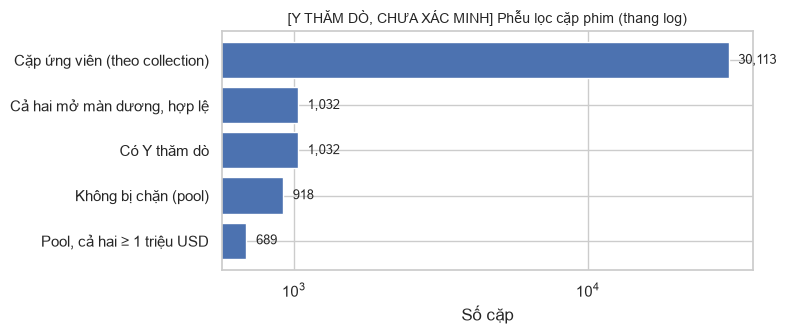

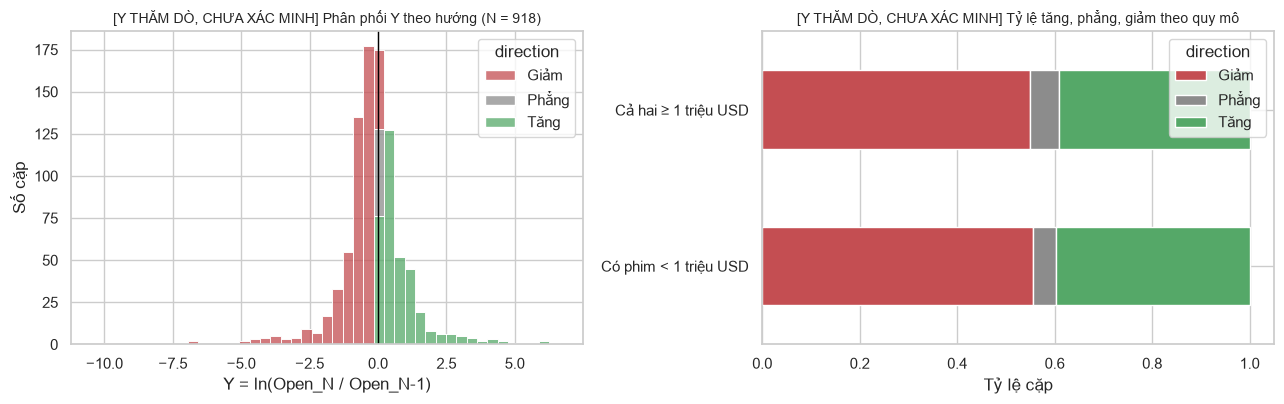

direction               Giảm  Phẳng   Tăng
scale                                     
Có phim < 1 triệu USD  0.555  0.048  0.397
Cả hai ≥ 1 triệu USD   0.549  0.060  0.392


In [7]:
# ---------- ACT 0: phễu lọc cặp ----------
n_all  = len(vp)
n_both = int(vp["both_openings_positive_valid"].sum())
n_y    = int(vp["Y"].notna().sum())
n_pool = len(v)
n_wide = int((v["scale"] == "Cả hai ≥ 1 triệu USD").sum())
funnel = pd.DataFrame({
    "Bước": ["Cặp ứng viên (theo collection)", "Cả hai mở màn dương, hợp lệ",
             "Có Y thăm dò", "Không bị chặn (pool)", "Pool, cả hai ≥ 1 triệu USD"],
    "Số cặp": [n_all, n_both, n_y, n_pool, n_wide]})
funnel["% so với bước đầu"] = (funnel["Số cặp"] / n_all * 100).round(1)
print(funnel.to_string(index=False))

v["abs_Y"] = v["Y"].abs()                       # độ lớn thay đổi, bỏ qua hướng
FLAT = 0.05                                     # ngưỡng "phẳng": giả định, có thể đổi
v["direction"] = np.select([v["Y"] > FLAT, v["Y"] < -FLAT], ["Tăng", "Giảm"], default="Phẳng")
print(v["direction"].value_counts())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(funnel["Bước"][::-1], funnel["Số cặp"][::-1], color="#4C72B0")
ax.set_xscale("log")
for i, n in enumerate(funnel["Số cặp"][::-1]):
    ax.text(n * 1.08, i, f"{n:,}", va="center", fontsize=9)
ax.set_title(TAG + "Phễu lọc cặp phim (thang log)", fontsize=10)
ax.set_xlabel("Số cặp")
plt.tight_layout(); plt.savefig("figures/b0_funnel.png", dpi=200); plt.show()

# ---------- ACT 1: phân phối Y theo hướng ----------
dir_colors = {"Tăng": "#55A868", "Giảm": "#C44E52", "Phẳng": "#8C8C8C"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(data=v, x="Y", hue="direction", palette=dir_colors, bins=45,
             multiple="stack", hue_order=["Giảm", "Phẳng", "Tăng"], ax=ax[0])
ax[0].axvline(0, color="black", lw=1)
ax[0].set_title(TAG + f"Phân phối Y theo hướng (N = {len(v)})", fontsize=10)
ax[0].set_xlabel("Y = ln(Open_N / Open_N-1)"); ax[0].set_ylabel("Số cặp")
share = (v.groupby("scale")["direction"].value_counts(normalize=True).unstack().fillna(0)[["Giảm", "Phẳng", "Tăng"]])
share.plot(kind="barh", stacked=True, color=[dir_colors[c] for c in share.columns], ax=ax[1])
ax[1].set_title(TAG + "Tỷ lệ tăng, phẳng, giảm theo quy mô", fontsize=10)
ax[1].set_xlabel("Tỷ lệ cặp"); ax[1].set_ylabel("")
plt.tight_layout(); plt.savefig("figures/b1_direction.png", dpi=200); plt.show()
print((v.groupby("scale")["direction"].value_counts(normalize=True).unstack().round(3)))

                       Số cặp  Mean Y  Median Y  % theo median  % theo mean  Trung bình nhân của tỷ lệ Open_N/Open_N-1
Có phim < 1 triệu USD   229.0  -0.266    -0.412        -33.766      -23.381                                      0.766
Cả hai ≥ 1 triệu USD    689.0  -0.105    -0.120        -11.275       -9.992                                      0.900
Tất cả                  918.0  -0.145    -0.147        -13.658      -13.537                                      0.865


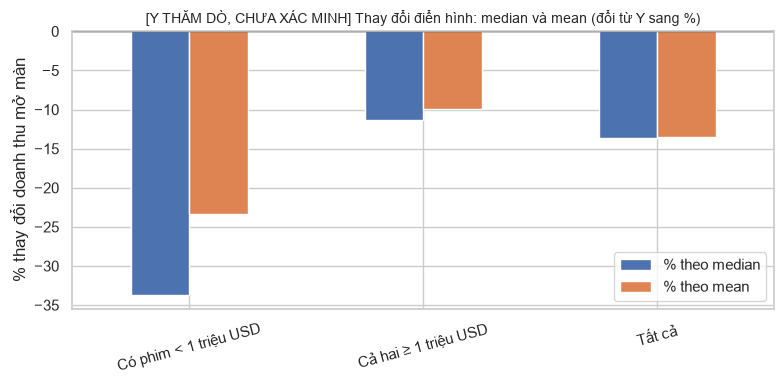

--- 8 cặp giảm mạnh nhất ---


KeyError: "['open_prev', 'open_curr'] not in index"

In [8]:
# ---------- ACT 2: điển hình và cực đoan ----------
def summarize(g):
    return pd.Series({
        "Số cặp": len(g),
        "Mean Y": g["Y"].mean(),
        "Median Y": g["Y"].median(),
        "% theo median": (np.exp(g["Y"].median()) - 1) * 100,
        "% theo mean": (np.exp(g["Y"].mean()) - 1) * 100,
        "Trung bình nhân của tỷ lệ Open_N/Open_N-1": np.exp(g["Y"].mean()),
    })

by_scale = v.groupby("scale").apply(summarize, include_groups=False)
all_row = summarize(v).rename("Tất cả")
tbl = pd.concat([by_scale, all_row.to_frame().T]).round(3)
print(tbl.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
plot_df = tbl[["% theo median", "% theo mean"]]
plot_df.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.axhline(0, color="black", lw=1)
ax.set_title(TAG + "Thay đổi điển hình: median và mean (đổi từ Y sang %)", fontsize=10)
ax.set_ylabel("% thay đổi doanh thu mở màn"); ax.set_xlabel("")
ax.tick_params(axis="x", rotation=15); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/b2_typical.png", dpi=200); plt.show()

cols = ["title_prev", "title_curr", "open_prev", "open_curr", "Y", "scale", "gap_years"]
print("--- 8 cặp giảm mạnh nhất ---")
print(v.nsmallest(8, "Y")[cols].to_string())
print("--- 8 cặp tăng mạnh nhất ---")
print(v.nlargest(8, "Y")[cols].to_string())

In [9]:
cols = ["title_prev", "title_curr", "open_n1", "open_n", "Y", "scale", "gap_years"]
print("--- 8 cặp giảm mạnh nhất ---")
print(v.nsmallest(8, "Y")[cols].to_string())
print("--- 8 cặp tăng mạnh nhất ---")
print(v.nlargest(8, "Y")[cols].to_string())

--- 8 cặp giảm mạnh nhất ---
                                        title_prev                                 title_curr     open_n1    open_n          Y                  scale  gap_years
5691                         The Amityville Horror                  Amityville: The Awakening  23507007.0     742.0 -10.363460  Có phim < 1 triệu USD  12.210815
3840                                 The Protector                            The Protector 2   5034180.0     270.0  -9.833339  Có phim < 1 triệu USD   8.199863
2551                   The Philadelphia Experiment                 Philadelphia Experiment II   1877000.0    1926.0  -6.881985  Có phim < 1 triệu USD   9.103354
1427                            Jeepers Creepers 2                         Jeepers Creepers 3  15269324.0   19151.0  -6.681246  Có phim < 1 triệu USD  14.135524
514                        Exorcist: The Beginning          Dominion: Prequel to The Exorcist  18054001.0  140703.0  -4.854471  Có phim < 1 triệu USD   0.747433
3971 

                       count   mean    std    min    25%    50%    75%     max
scale                                                                         
Có phim < 1 triệu USD  229.0  1.747  1.684  0.000  0.562  1.202  2.550  10.363
Cả hai ≥ 1 triệu USD   689.0  0.533  0.445  0.005  0.199  0.421  0.732   2.616
 Ngưỡng (USD)  Số cặp nhóm nhỏ  Số cặp nhóm lớn  Std Y nhóm lớn  Median Y nhóm lớn  Median |Y| nhóm lớn  Tỷ lệ giảm nhóm lớn  Std Y nhóm nhỏ
       100000              136              782           0.966             -0.128                0.462                0.568           2.620
       500000              191              727           0.784             -0.120                0.440                0.568           2.520
      1000000              229              689           0.686             -0.120                0.421                0.567           2.415
      5000000              336              582           0.603             -0.108                0.383                0

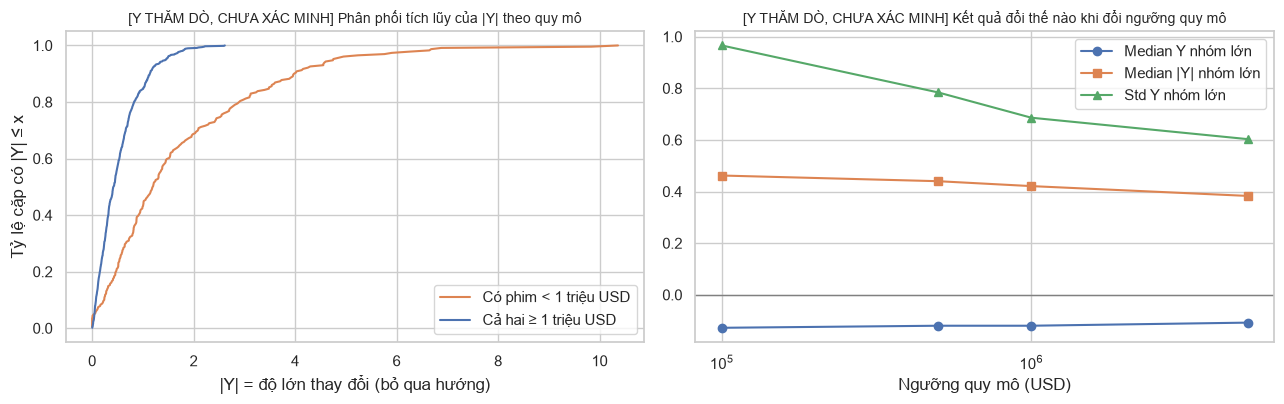

In [10]:
# ---------- ACT 3: |Y| theo quy mô ----------
print(v.groupby("scale")["abs_Y"].describe().round(3).to_string())

thresholds = [1e5, 5e5, 1e6, 5e6]
rows = []
for t in thresholds:
    small = (v["open_n1"] < t) | (v["open_n"] < t)
    w, s = v[~small], v[small]
    rows.append({"Ngưỡng (USD)": int(t), "Số cặp nhóm nhỏ": int(small.sum()), "Số cặp nhóm lớn": len(w),
                 "Std Y nhóm lớn": w["Y"].std(), "Median Y nhóm lớn": w["Y"].median(),
                 "Median |Y| nhóm lớn": w["abs_Y"].median(),
                 "Tỷ lệ giảm nhóm lớn": (w["Y"] < 0).mean(),
                 "Std Y nhóm nhỏ": s["Y"].std() if len(s) > 1 else np.nan})
ladder = pd.DataFrame(rows).round(3)
print(ladder.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, g in v.groupby("scale"):
    x = np.sort(g["abs_Y"]); ax[0].plot(x, np.arange(1, len(x) + 1) / len(x), label=name, color=palette[name])
ax[0].set_title(TAG + "Phân phối tích lũy của |Y| theo quy mô", fontsize=10)
ax[0].set_xlabel("|Y| = độ lớn thay đổi (bỏ qua hướng)"); ax[0].set_ylabel("Tỷ lệ cặp có |Y| ≤ x"); ax[0].legend()
ax[1].plot(ladder["Ngưỡng (USD)"], ladder["Median Y nhóm lớn"], marker="o", label="Median Y nhóm lớn")
ax[1].plot(ladder["Ngưỡng (USD)"], ladder["Median |Y| nhóm lớn"], marker="s", label="Median |Y| nhóm lớn")
ax[1].plot(ladder["Ngưỡng (USD)"], ladder["Std Y nhóm lớn"], marker="^", label="Std Y nhóm lớn")
ax[1].set_xscale("log"); ax[1].axhline(0, color="gray", lw=1)
ax[1].set_title(TAG + "Kết quả đổi thế nào khi đổi ngưỡng quy mô", fontsize=10)
ax[1].set_xlabel("Ngưỡng quy mô (USD)"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/b3_scale_ladder.png", dpi=200); plt.show()

                 Biến                         Thời điểm   n  Spearman với Y  Spearman với |Y|
  audience_score_prev                      Có điều kiện 676           0.342            -0.071
    critic_score_prev                      Có điều kiện 674           0.334            -0.084
       rt_critic_curr Sau khi phát hành (chỉ chẩn đoán) 676           0.325            -0.123
        budget_change                      Có điều kiện 650           0.306             0.027
     rt_audience_curr Sau khi phát hành (chỉ chẩn đoán) 682           0.274            -0.085
     log1p_votes_curr Sau khi phát hành (chỉ chẩn đoán) 689           0.272            -0.100
   collection_n_films                      Có điều kiện 689           0.243            -0.190
     log1p_votes_prev                      Có điều kiện 689           0.182            -0.053
          log_open_n1                      Có điều kiện 689          -0.142            -0.145
  cast_retention_rate          Biết trước khi phát hành 689 

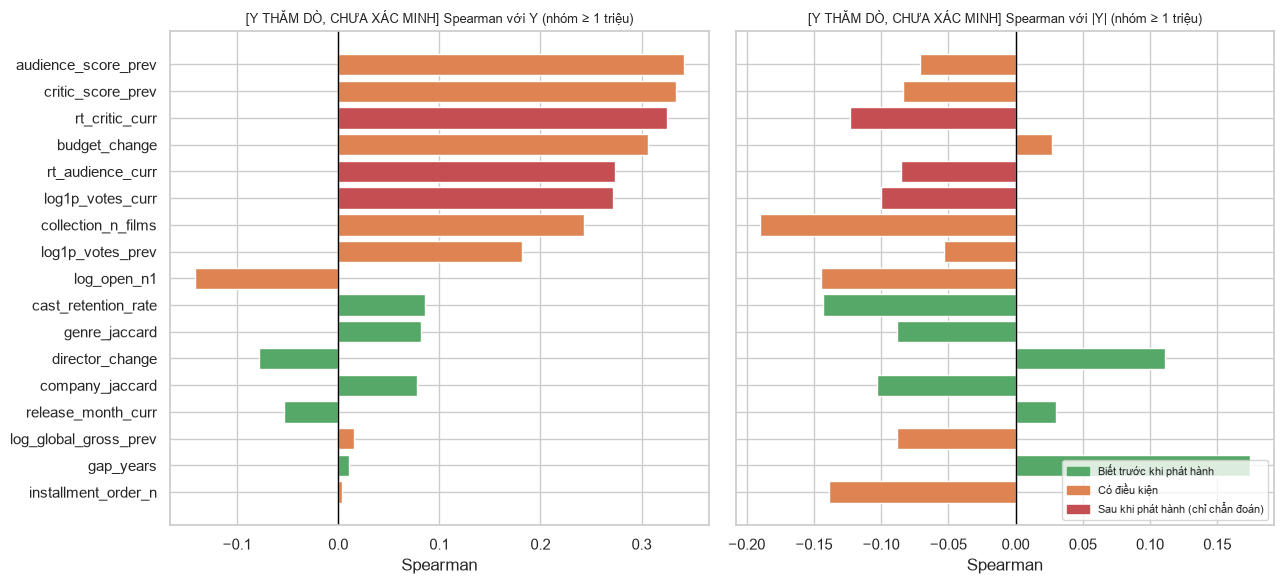

In [11]:
# ---------- ACT 4: yếu tố liên quan đến Y và |Y| ----------
avail = {
    "gap_years": "Biết trước khi phát hành", "director_change": "Biết trước khi phát hành",
    "cast_retention_rate": "Biết trước khi phát hành", "company_jaccard": "Biết trước khi phát hành",
    "genre_jaccard": "Biết trước khi phát hành", "release_month_curr": "Biết trước khi phát hành",
    "budget_change": "Có điều kiện", "log_open_n1": "Có điều kiện", "log_global_gross_prev": "Có điều kiện",
    "critic_score_prev": "Có điều kiện", "audience_score_prev": "Có điều kiện", "log1p_votes_prev": "Có điều kiện",
    "installment_order_n": "Có điều kiện", "collection_n_films": "Có điều kiện",
    "rt_critic_curr": "Sau khi phát hành (chỉ chẩn đoán)", "rt_audience_curr": "Sau khi phát hành (chỉ chẩn đoán)",
    "log1p_votes_curr": "Sau khi phát hành (chỉ chẩn đoán)",
}
avail_colors = {"Biết trước khi phát hành": "#55A868", "Có điều kiện": "#DD8452",
                "Sau khi phát hành (chỉ chẩn đoán)": "#C44E52"}

wide = v[v["scale"] == "Cả hai ≥ 1 triệu USD"]

def rho(df, x, y):
    d = df[[x, y]].dropna()
    return (d[x].rank().corr(d[y].rank()), len(d)) if len(d) > 10 else (np.nan, len(d))

rows = []
for x, a in avail.items():
    ry, n = rho(wide, x, "Y"); ra, _ = rho(wide, x, "abs_Y")
    rows.append({"Biến": x, "Thời điểm": a, "n": n, "Spearman với Y": ry, "Spearman với |Y|": ra})
res = pd.DataFrame(rows).round(3).sort_values("Spearman với Y", key=abs, ascending=False)
print(res.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
order = res["Biến"].tolist()[::-1]
for a_, col in zip(ax, ["Spearman với Y", "Spearman với |Y|"]):
    d = res.set_index("Biến").loc[order]
    a_.barh(order, d[col], color=[avail_colors[t] for t in d["Thời điểm"]])
    a_.axvline(0, color="black", lw=1); a_.set_title(TAG + col + " (nhóm ≥ 1 triệu)", fontsize=9)
    a_.set_xlabel("Spearman")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in avail_colors.values()]
ax[1].legend(handles, avail_colors.keys(), loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig("figures/b4_factors.png", dpi=200); plt.show()

Theo giai đoạn (nhóm ≥ 1 triệu):
            Số cặp  Median Y  Tỷ lệ giảm
era                                     
Trước 2000     193    -0.066       0.539
2000-2009      148     0.014       0.493
2010-2019      232    -0.194       0.629
Từ 2020        116    -0.111       0.586
Theo thứ tự phần (nhóm ≥ 1 triệu):
           Số cặp  Median Y  Tỷ lệ giảm
order_grp                              
2             384    -0.107       0.560
3             150    -0.181       0.627
4              67     0.035       0.448
5+             88    -0.192       0.591


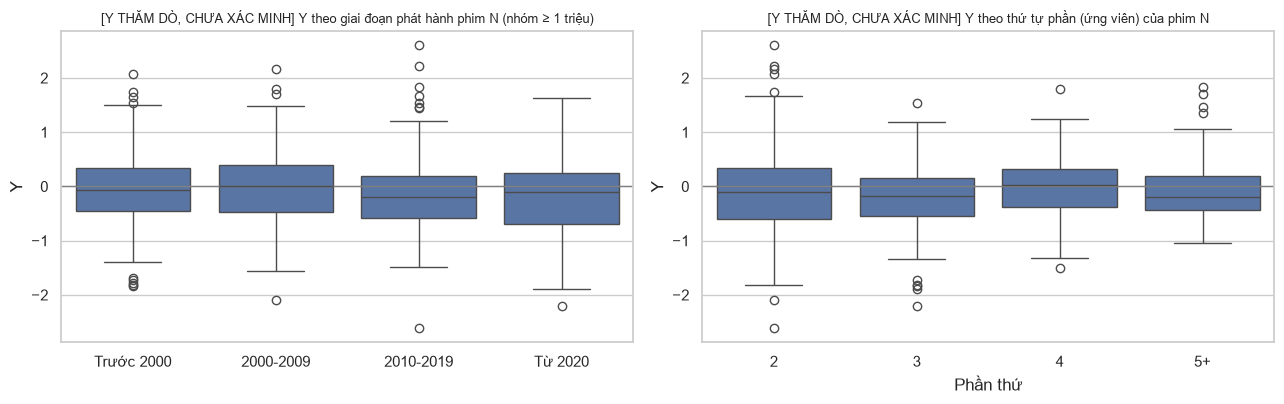

Collection có ≥ 3 phim: 195 | tỷ lệ phim cuối thấp hơn phim đầu: 0.482


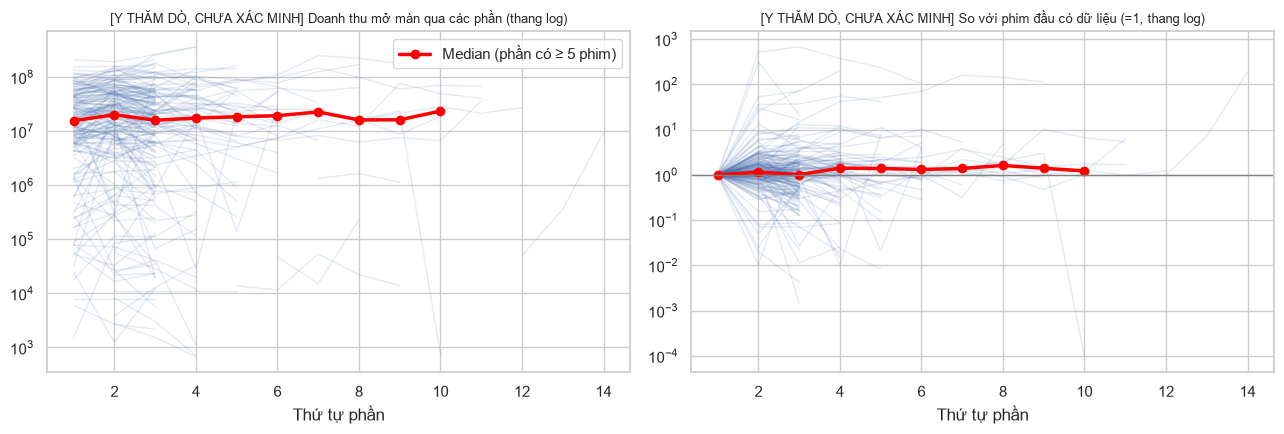

In [12]:
# ---------- ACT 5: quỹ đạo ----------
v["year_curr"] = pd.to_datetime(v["release_date_curr"], errors="coerce").dt.year
v["era"] = pd.cut(v["year_curr"], [0, 1999, 2009, 2019, 2100],
                  labels=["Trước 2000", "2000-2009", "2010-2019", "Từ 2020"])
v["order_grp"] = v["installment_order_n"].clip(upper=5).astype(str).replace({"5": "5+"})
wide = v[v["scale"] == "Cả hai ≥ 1 triệu USD"]

for name, key in [("giai đoạn", "era"), ("thứ tự phần", "order_grp")]:
    t = wide.groupby(key, observed=True)["Y"].agg(["count", "median", lambda s: (s < 0).mean()])
    t.columns = ["Số cặp", "Median Y", "Tỷ lệ giảm"]
    print("Theo", name, "(nhóm ≥ 1 triệu):"); print(t.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(data=wide, x="era", y="Y", ax=ax[0], color="#4C72B0")
ax[0].axhline(0, color="gray", lw=1)
ax[0].set_title(TAG + "Y theo giai đoạn phát hành phim N (nhóm ≥ 1 triệu)", fontsize=9); ax[0].set_xlabel("")
sns.boxplot(data=wide, x="order_grp", y="Y", order=["2", "3", "4", "5+"], ax=ax[1], color="#4C72B0")
ax[1].axhline(0, color="gray", lw=1)
ax[1].set_title(TAG + "Y theo thứ tự phần (ứng viên) của phim N", fontsize=9); ax[1].set_xlabel("Phần thứ")
plt.tight_layout(); plt.savefig("figures/b5_era_order.png", dpi=200); plt.show()

# quỹ đạo từng nhượng quyền (collection có ít nhất 3 phim trong các cặp đang xét)
a = v[["franchise_id", "installment_order_n", "open_n"]].rename(columns={"installment_order_n": "order", "open_n": "open"})
b = v[["franchise_id", "installment_order_n", "open_n1"]].assign(order=lambda d: d["installment_order_n"] - 1)\
      .rename(columns={"open_n1": "open"})[["franchise_id", "order", "open"]]
tj = pd.concat([a, b]).drop_duplicates(["franchise_id", "order"]).sort_values(["franchise_id", "order"])
tj = tj[tj.groupby("franchise_id")["order"].transform("count") >= 3]
first_last = tj.groupby("franchise_id")["open"].agg(first="first", last="last")
print("Collection có ≥ 3 phim:", len(first_last),
      "| tỷ lệ phim cuối thấp hơn phim đầu:", round((first_last["last"] < first_last["first"]).mean(), 3))
tj["rel"] = tj["open"] / tj.groupby("franchise_id")["open"].transform("first")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for _, g in tj.groupby("franchise_id"):
    ax[0].plot(g["order"], g["open"], color="#4C72B0", alpha=0.15, lw=1)
    ax[1].plot(g["order"], g["rel"], color="#4C72B0", alpha=0.15, lw=1)
med = tj.groupby("order").filter(lambda g: len(g) >= 5).groupby("order")
ax[0].plot(med["open"].median().index, med["open"].median().values, color="red", marker="o", lw=2.5, label="Median (phần có ≥ 5 phim)")
ax[1].plot(med["rel"].median().index, med["rel"].median().values, color="red", marker="o", lw=2.5, label="Median (phần có ≥ 5 phim)")
ax[0].set_yscale("log"); ax[1].set_yscale("log"); ax[1].axhline(1, color="gray", lw=1)
ax[0].set_title(TAG + "Doanh thu mở màn qua các phần (thang log)", fontsize=9)
ax[1].set_title(TAG + "So với phim đầu có dữ liệu (=1, thang log)", fontsize=9)
ax[0].set_xlabel("Thứ tự phần"); ax[1].set_xlabel("Thứ tự phần"); ax[0].legend()
plt.tight_layout(); plt.savefig("figures/b5_trajectories.png", dpi=200); plt.show()

Cả hai ≥ 1 triệu USD | số cặp: 689 | số collection: 403
                               MAE   RMSE  R² so với median
Dự đoán Y = 0 (không đổi)    0.533  0.694            -0.017
Median của tập train         0.527  0.688             0.000
Hồi quy 1 biến: log_open_n1  0.526  0.675             0.038 

Toàn bộ 918 cặp | số cặp: 918 | số collection: 562
                               MAE   RMSE  R² so với median
Dự đoán Y = 0 (không đổi)    0.836  1.352            -0.011
Median của tập train         0.827  1.344             0.000
Hồi quy 1 biến: log_open_n1  0.836  1.324             0.030 



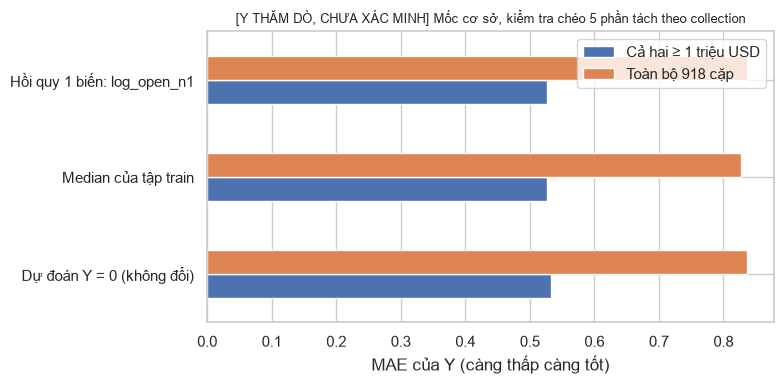

In [13]:
# ---------- ACT 6: baseline, tách theo collection ----------
rng = np.random.default_rng(42)
d = v[["franchise_id", "log_open_n1", "Y", "scale"]].dropna().reset_index(drop=True)
ids = d["franchise_id"].unique(); rng.shuffle(ids)
d["fold"] = d["franchise_id"].map({f: i % 5 for i, f in enumerate(ids)})

def cv(df):
    p0 = np.zeros(len(df)); pm = np.zeros(len(df)); pr = np.zeros(len(df))
    for k in range(5):
        tr, te = (df["fold"] != k).values, (df["fold"] == k).values
        pm[te] = df.loc[tr, "Y"].median()
        b, a = np.polyfit(df.loc[tr, "log_open_n1"], df.loc[tr, "Y"], 1)
        pr[te] = a + b * df.loc[te, "log_open_n1"]
    y = df["Y"].values
    rows = {}
    for name, p in [("Dự đoán Y = 0 (không đổi)", p0), ("Median của tập train", pm), ("Hồi quy 1 biến: log_open_n1", pr)]:
        rows[name] = {"MAE": np.abs(y - p).mean(), "RMSE": np.sqrt(((y - p) ** 2).mean()),
                      "R² so với median": 1 - ((y - p) ** 2).sum() / ((y - pm) ** 2).sum()}
    return pd.DataFrame(rows).T

groups = {"Cả hai ≥ 1 triệu USD": d[d["scale"] == "Cả hai ≥ 1 triệu USD"].reset_index(drop=True),
          "Toàn bộ 918 cặp": d}
tabs = {}
for g, df in groups.items():
    tabs[g] = cv(df)
    print(g, "| số cặp:", len(df), "| số collection:", df["franchise_id"].nunique())
    print(tabs[g].round(3).to_string(), "\n")

fig, ax = plt.subplots(figsize=(8, 4))
pd.DataFrame({g: t["MAE"] for g, t in tabs.items()}).plot.barh(ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_xlabel("MAE của Y (càng thấp càng tốt)")
ax.set_title(TAG + "Mốc cơ sở, kiểm tra chéo 5 phần tách theo collection", fontsize=9)
plt.tight_layout(); plt.savefig("figures/b6_baseline.png", dpi=200); plt.show()

In [14]:
# ---------- ACT 7: tổng hợp ----------
synth = pd.DataFrame([
 ["RQ1 Dự đoán thay đổi %", "Mốc cơ sở nhóm ≥ 1 triệu: MAE 0,526; R² 0,038 (hồi quy log_open_n1, chia theo collection)",
  "Mô hình phải vượt MAE 0,526 và R² 0,04; chia train/test theo collection"],
 ["RQ1 Dự đoán thay đổi %", "Điểm RT/vote của phim N liên hệ Y ≈ 0,33/0,27 nhưng là thông tin sau phát hành",
  "Loại khỏi RQ1 (rò rỉ); chỉ dùng chẩn đoán"],
 ["RQ1 Dự đoán thay đổi %", "collection_n_films liên hệ Y 0,24, biết đầy đủ chỉ sau khi cả loạt ra xong",
  "Không dùng (nghi thiên lệch sống sót)"],
 ["RQ2 Yếu tố tăng/giảm", "Điểm audience/critic trước (0,34/0,33) và budget_change (0,31) liên hệ hướng, không liên hệ độ lớn",
  "Dùng cho mô tả/giải thích; kiểm tra biến nào biết trước khi phát hành"],
 ["RQ2 Yếu tố tăng/giảm", "gap_years liên hệ |Y| 0,17 nhưng không liên hệ Y 0,01",
  "Cân nhắc làm mục tiêu phụ |Y|; nghỉ càng lâu, thay đổi càng lớn"],
 ["RQ2 Yếu tố tăng/giảm", "Biến biết sớm (giữ diễn viên, đổi đạo diễn, đổi hãng, thể loại, tháng): |ρ| ≤ 0,09",
  "Giữ làm biến phụ, không kỳ vọng mạnh"],
 ["RQ3 Quy luật theo phần", "Median Y theo thứ tự phần và giai đoạn không đơn điệu; 48,2% collection ≥ 3 phim có phim cuối thấp hơn phim đầu",
  "Không có bằng chứng cho 'càng về sau càng yếu'; thứ tự phần chỉ là ứng viên"],
 ["Quy mô chung", "Nhóm có phim < 1 triệu USD: std Y 2,4 so với 0,69 và MAE 0,83 so với 0,53",
  "Tách hai nhóm khi mô hình hóa; không gộp một mô hình"],
], columns=["Câu hỏi", "Bằng chứng", "Quyết định cho bước sau"])
pd.set_option("display.max_colwidth", None)
print(synth.to_string(index=False))
synth.to_csv("figures/b7_tong_hop.csv", index=False, encoding="utf-8-sig")

print("""
HẠN CHẾ:
1. Y chưa xác minh (cặp, thị trường, đơn vị tiền, cửa sổ doanh thu).
2. 'Collection' không bằng 'nhượng quyền'; thứ tự phần là ứng viên theo ngày phát hành.
3. Thiên lệch sống sót: loạt càng dài càng là loạt thành công.
4. Cột sau phát hành (rt_*_curr, log1p_votes_curr) chỉ chẩn đoán.
5. Ngưỡng 1 triệu USD và FLAT = 0,05 do mình chọn.
6. Tương quan Spearman không phải quan hệ nhân quả.
""")

               Câu hỏi                                                                                                      Bằng chứng                                                     Quyết định cho bước sau
RQ1 Dự đoán thay đổi %                       Mốc cơ sở nhóm ≥ 1 triệu: MAE 0,526; R² 0,038 (hồi quy log_open_n1, chia theo collection)     Mô hình phải vượt MAE 0,526 và R² 0,04; chia train/test theo collection
RQ1 Dự đoán thay đổi %                                  Điểm RT/vote của phim N liên hệ Y ≈ 0,33/0,27 nhưng là thông tin sau phát hành                                   Loại khỏi RQ1 (rò rỉ); chỉ dùng chẩn đoán
RQ1 Dự đoán thay đổi %                                      collection_n_films liên hệ Y 0,24, biết đầy đủ chỉ sau khi cả loạt ra xong                                       Không dùng (nghi thiên lệch sống sót)
  RQ2 Yếu tố tăng/giảm              Điểm audience/critic trước (0,34/0,33) và budget_change (0,31) liên hệ hướng, không liên hệ độ lớn       Dùng cho mô tả/